# Bloc 1 — Exploration des données (EDA)
**Fichiers (Public records)** : `officer_filings`, `public_appointments`, `licensed_facilities`, `licensed_professionals`, `institutional_memos`, `public_and_investigative_documents` (versions `_cleaned`).

Pour chaque fichier : (on suit la TODO)
1. **Inventaire et typage** des variables (identifiants, nominales, ordinales, numériques, dates, texte) ;
2. **Variables construites** : les dates sont transformées en durées et en années, pour pouvoir les analyser ;
3. **Statistiques descriptives et distributions** (moyenne, médiane, écart-type, quartiles, skewness, test de Shapiro-Wilk, histogrammes et boxplots) ;
4. **Variables catégorielles** (comptages, barplots) ;
5. **Corrélations** (Pearson et Spearman) quand il y a au moins deux variables numériques.

TOutes les étapes ne peuvent pas être appliquées à chaques fichiers, quand c'est inutile on passe (avec justification).

Décision : date de référence. On retrouve des mandants dans quelques fichiers, ceux qui sont en cours n'ont pas de date de fin donc pour mesurer une durée (ce qui nous aideras à analyse), on les arrête au 31/12/2025 (les données les plus récentes datant de 2025).

In [3]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
REF_DATE = pd.Timestamp("2025-12-31")

In [4]:
officers = pd.read_csv("officer_filings_cleaned.csv", parse_dates=["appointment_date", "cessation_date", "filing_date"])
appointments = pd.read_csv("public_appointments_cleaned.csv", parse_dates=["appointment_start", "appointment_end"])
facilities = pd.read_csv("licensed_facilities_cleaned.csv", parse_dates=["license_start"])
professionals = pd.read_csv("licensed_professionals_cleaned.csv", parse_dates=["license_issue_date"])
memos = pd.read_csv("institutional_memos_cleaned.csv", parse_dates=["document_date"])
documents = pd.read_csv("public_and_investigative_documents_cleaned.csv", parse_dates=["document_date"])
entities = pd.read_csv("registered_entities_cleaned.csv")   # seulement pour le nom des entreprises
reg_name = dict(zip(entities["registration_number"], entities["legal_name"]))

## 0. Fonctions communes

In [5]:
def inventaire(df):
    # type, nombre de valeurs distinctes et de manquants pour chaque colonne
    print("Dimensions :", df.shape)
    return pd.DataFrame({"type": df.dtypes.astype(str), "valeurs_distinctes": df.nunique(), "manquants": df.isna().sum()})


def describe_numeric(df, cols):
    # statistiques descriptives + test de normalité de Shapiro-Wilk (p < 0.05 : pas normale)
    res = pd.DataFrame({
        "n": df[cols].count(), "manquants": df[cols].isna().sum(),
        "moyenne": df[cols].mean(), "écart-type": df[cols].std(),
        "min": df[cols].min(), "Q1": df[cols].quantile(.25), "médiane": df[cols].median(),
        "Q3": df[cols].quantile(.75), "max": df[cols].max(), "skewness": df[cols].skew(),
    })
    res["shapiro_p"] = [stats.shapiro(df[c].dropna()).pvalue for c in cols]
    return res.round(3)


def distributions(df, cols, nom=""):
    # histogramme (à gauche) et boxplot (à droite) pour chaque variable numérique
    fig, ax = plt.subplots(len(cols), 2, figsize=(11, 2.6 * len(cols)), squeeze=False)
    for i, c in enumerate(cols):
        sns.histplot(df[c].dropna(), kde=True, ax=ax[i, 0]); ax[i, 0].set_title(f"{nom} — histogramme : {c}")
        sns.boxplot(x=df[c].dropna(), ax=ax[i, 1]); ax[i, 1].set_title(f"{nom} — boxplot : {c}")
    plt.tight_layout(); plt.show()


def barplots(df, cols, nom=""):
    # comptage des modalités de chaque variable catégorielle (barres horizontales, triées)
    fig, ax = plt.subplots(1, len(cols), figsize=(5 * len(cols), 4), squeeze=False)
    for a, c in zip(ax[0], cols):
        df[c].fillna("(manquant)").value_counts().sort_values().plot.barh(ax=a, title=f"{nom} — {c}")
        a.set_ylabel("")
    plt.tight_layout(); plt.show()


def correlations(df, cols, nom=""):
    # matrices de corrélation de Pearson (linéaire) et de Spearman (rangs, robuste)
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
    for a, m in zip(ax, ["pearson", "spearman"]):
        sns.heatmap(df[cols].corr(method=m), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=a)
        a.set_title(f"{nom} — {m.capitalize()}")
    plt.tight_layout(); plt.show()

---
## 1. officer_filings
### 1.1 Inventaire et typage

In [6]:
inventaire(officers)

Dimensions : (135, 12)


,type,valeurs_distinctes,manquants
filing_id,str,135,0
registration_number,str,24,0
officer_local_ref,str,104,0
full_name,str,104,0
birth_year_or_age_band,str,50,0
nationality_or_region,str,5,0
role_title,str,54,0
appointment_date,datetime64[us],52,0
cessation_date,datetime64[us],37,77
filing_date,datetime64[us],133,0


- 135 déclarations (`filing_id` unique), **104 personnes** (`officer_local_ref`, `full_name`) et **24 entreprises** (`registration_number`) : une même personne peut avoir plusieurs mandats, parfois dans des entreprises différentes.
- `cessation_date` a 77 manquants : hypothèse, ce sont des mandats encore actifs (vérifié en 1.4).

**Typage** :
- identifiants : `filing_id`, `registration_number`, `officer_local_ref` ;
- nominales non ordonnées : `nationality_or_region` (5), `service_address` (12), `filing_status` (2), `role_title` (54 modalités pour 135 lignes, presque du texte libre) ;
- variable mixte : `birth_year_or_age_band` contient soit une année exacte (« 1971 »), soit une tranche (« 1970–1979 ») ;
- dates : `appointment_date`, `cessation_date`, `filing_date`.

### 1.2 Variables construites

In [7]:
of = officers.copy()
of["tenure_days"] = (of["cessation_date"] - of["appointment_date"]).dt.days          # durée du mandat (vide si en cours)
of["filing_delay_days"] = (of["filing_date"] - of["appointment_date"]).dt.days       # délai de déclaration
of["appointment_year"] = of["appointment_date"].dt.year
b = of["birth_year_or_age_band"]
of["birth_year"] = pd.to_numeric(b.where(b.str.fullmatch(r"\d{4}")), errors="coerce")   # année exacte seulement
milieu_tranche = b.str.extract(r"(\d{4})\D+(\d{4})").astype(float).mean(axis=1)        # 1970–1979 -> 1974.5
of["birth_year_est"] = of["birth_year"].fillna(milieu_tranche)
of["age_at_appointment"] = of["appointment_year"] - of["birth_year_est"]
of["entity"] = of["registration_number"].map(reg_name)
of[["full_name", "appointment_date", "cessation_date", "tenure_days", "filing_delay_days", "birth_year_or_age_band", "birth_year_est", "age_at_appointment"]].head()

,full_name,appointment_date,cessation_date,tenure_days,filing_delay_days,birth_year_or_age_band,birth_year_est,age_at_appointment
0,Edward Vann,1840-01-01,1888-12-31,17897.0,68,1815,1815.0,25.0
1,Emil Warden,1895-01-01,1943-12-31,17895.0,12,1871,1871.0,24.0
2,Adrian Vosmere,1952-01-01,1991-12-31,14609.0,15,1920–1929,1924.5,27.5
3,Dr. Elias Voss,1996-01-01,NaT,NaN,45,1961,1961.0,35.0
4,J. Varlan,1885-01-01,1918-12-31,12416.0,72,1862,1862.0,23.0


Les dates ne se prêtent pas directement aux statistiques : on les transforme en durées (mandat, délai de déclaration) et en années. La colonne de naissance est séparée en année exacte (`birth_year`) et année estimée au milieu de la tranche (`birth_year_est`), pour calculer un âge approché.

### 1.3 Statistiques descriptives et distributions

In [8]:
num_of = ["tenure_days", "filing_delay_days", "appointment_year", "birth_year", "age_at_appointment"]
describe_numeric(of, num_of)

,n,manquants,moyenne,écart-type,min,Q1,médiane,Q3,max,skewness,shapiro_p
tenure_days,58,77,4151.103,4388.249,-367.0,1460.0,3286.0,4290.75,17897.0,1.723,0.0
filing_delay_days,135,0,44.578,19.276,10.0,28.0,48.0,62.50,74.0,-0.222,0.0
appointment_year,135,0,1996.289,23.627,1840.0,1990.0,1999.0,2008.50,2026.0,-3.750,0.0
birth_year,101,34,1968.564,25.666,1815.0,1962.0,1973.0,1983.00,1994.0,-3.579,0.0
age_at_appointment,135,0,28.081,4.593,19.5,24.0,27.0,31.00,43.5,0.730,0.0


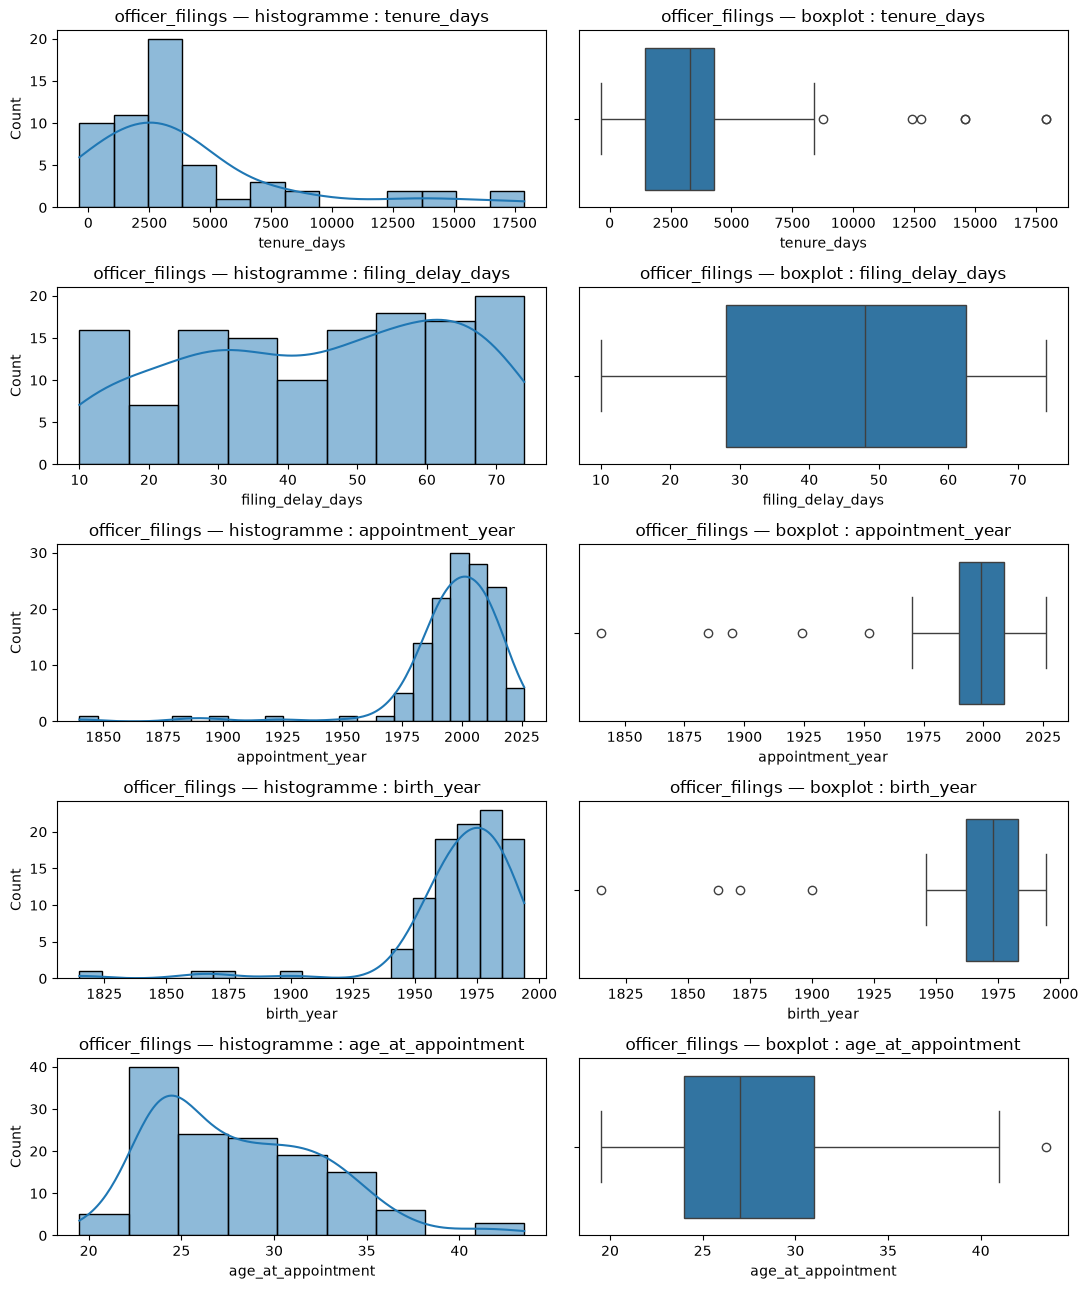

In [9]:
distributions(of, num_of, "officer_filings")

Aucune variable ne suit une loi normale (Shapiro-Wilk, p < 0,05), ni une loi de puissance. Le test ne dit pas *pourquoi* : ce sont les histogrammes qui le montrent.
- `filing_delay_days` est **uniforme** entre 10 et 74 jours, sans valeur extrême : tirage aléatoire probable, variable peu informative.
- `appointment_year` et `birth_year` sont très asymétriques vers la gauche (skewness ≈ −3,7) : presque tout est après 1970, mais **quelques déclarations remontent au XIXᵉ siècle** (nomination en 1840, naissance en 1815).
- `tenure_days` montre des mandats très longs (jusqu'à 49 ans) et des **durées négatives** (jusqu'à −367 jours), logiquement impossibles.
- `age_at_appointment` (médiane ≈ 27 ans, max 43,5) ne présente pas de valeur aberrante.
- La nomination la plus récente date de 2026, après la date de référence.

Ces points sont étudiés au bloc 3.

### 1.4 Variables catégorielles

cessation_date manquante  False  True 
filing_status                         
active                        0     77
historical                   58      0

Part des entreprises par juridiction : {'Valenne Republic': 0.5, 'Nordhaven Union': 0.21, 'Avelora Federation': 0.17, 'Kintara Republic': 0.08, 'Tembara Commonwealth': 0.04}
Part des dirigeants par nationalité : {'Valennan': 0.46, 'Nordhaven': 0.2, 'Aveloran': 0.14, 'Tembaran': 0.13, 'Kintaran': 0.07}


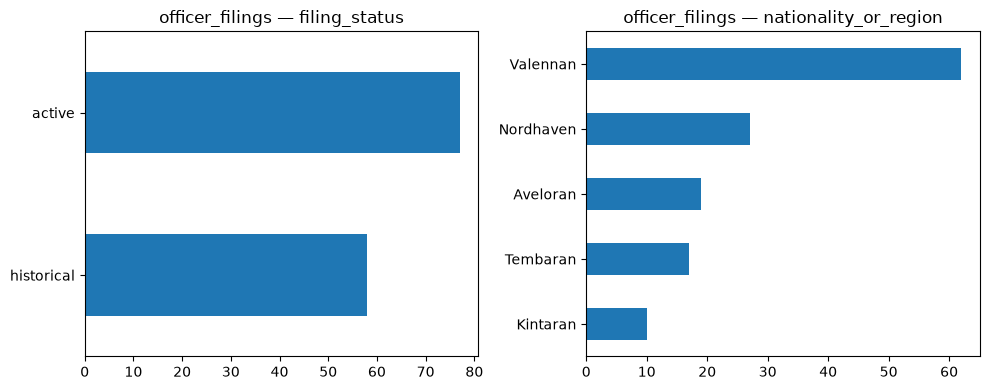

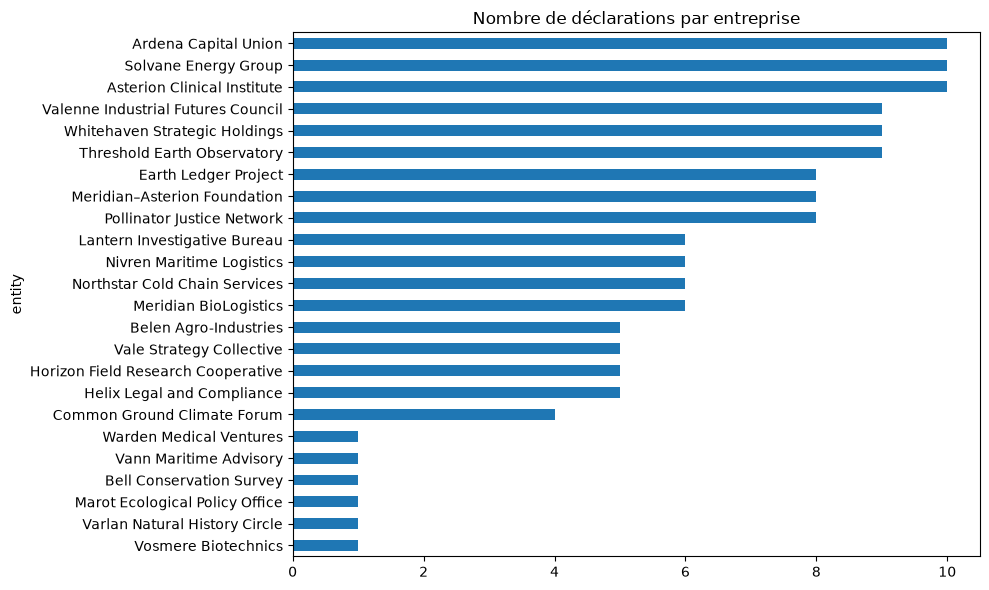

In [10]:
print(pd.crosstab(of["filing_status"], of["cessation_date"].isna(), colnames=["cessation_date manquante"]))
print("\nPart des entreprises par juridiction :", entities["jurisdiction"].value_counts(normalize=True).round(2).to_dict())
print("Part des dirigeants par nationalité :", of["nationality_or_region"].value_counts(normalize=True).round(2).to_dict())
barplots(of, ["filing_status", "nationality_or_region"], "officer_filings")
of["entity"].value_counts().sort_values().plot.barh(figsize=(10, 6), title="Nombre de déclarations par entreprise")
plt.tight_layout(); plt.show()

- `filing_status` est équilibrée (77 actives, 58 historiques). Les 77 `cessation_date` manquantes sont **exactement** les mandats actifs : ce sont des mandats en cours, pas des données perdues. On ne les impute pas.
- `nationality_or_region` est dominée par les Valennans (46 %), proche de la part des entreprises enregistrées en Valenne (50 %) : cela reflète le registre, rien de suspect.
- `role_title` (54 modalités) est presque du texte libre, peu exploitable par comptage.
- La plupart des entreprises ont 4 à 10 déclarations, mais **6 entreprises n'en ont qu'une** (Vann Maritime Advisory, Warden Medical Ventures, Vosmere Biotechnics, Varlan Natural History Circle, Bell Conservation Survey, Marot Ecological Policy Office) : les entreprises des nominations les plus anciennes.

### 1.5 Corrélations

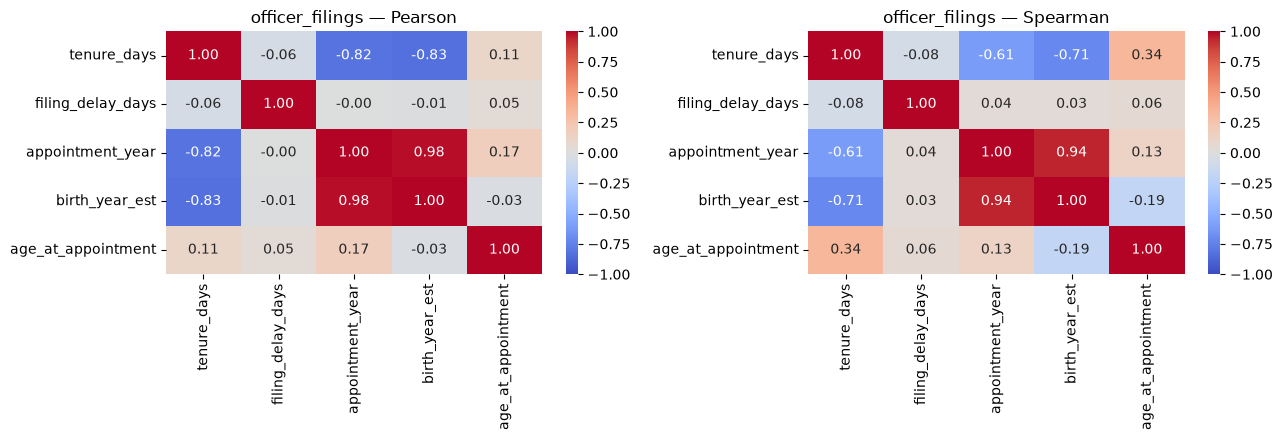

Pearson durée / année, toutes les lignes : -0.82
Pearson durée / année, sans les nominations avant 1960 : -0.49


In [11]:
corr_of = ["tenure_days", "filing_delay_days", "appointment_year", "birth_year_est", "age_at_appointment"]
correlations(of, corr_of, "officer_filings")
recent = of[of["appointment_year"] >= 1960]
print("Pearson durée / année, toutes les lignes :", round(of["tenure_days"].corr(of["appointment_year"]), 2))
print("Pearson durée / année, sans les nominations avant 1960 :", round(recent["tenure_days"].corr(recent["appointment_year"]), 2))

- `appointment_year` et `birth_year_est` sont très fortement corrélées (0,98 / 0,94) : mécanique, on est nommé quelques décennies après sa naissance.
- `tenure_days` est négativement corrélée à `appointment_year` (Pearson −0,82, Spearman −0,61). L'écart entre les deux vient de quelques mandats très anciens : sans les nominations avant 1960, Pearson tombe à −0,49.
- `filing_delay_days` n'est corrélée à rien, ce qui confirme son caractère aléatoire.

Ce sont des relations de construction entre dates, pas des liens de cause à effet.

---
## 2. public_appointments
### 2.1 Inventaire et typage

In [12]:
inventaire(appointments)

Dimensions : (62, 12)


,type,valeurs_distinctes,manquants
appointment_record_id,str,62,0
appointing_jurisdiction,str,4,0
office_holder_name,str,50,0
recorded_birth_year,float64,28,6
office_title,str,28,0
institution_name,str,8,0
appointment_start,datetime64[us],38,0
appointment_end,datetime64[us],21,34
appointment_basis,str,1,0
departure_reason,str,3,34


In [13]:
print("appointment_basis :", appointments["appointment_basis"].unique().tolist())
print("official_region == appointing_jurisdiction partout :", (appointments["official_region"] == appointments["appointing_jurisdiction"]).all())
print("Fin manquante <=> pas de motif de départ :", (appointments["appointment_end"].isna() == appointments["departure_reason"].isna()).all())
print("Personnes distinctes :", appointments["office_holder_name"].nunique(), "pour", len(appointments), "nominations")

appointment_basis : ['appointed']
official_region == appointing_jurisdiction partout : True
Fin manquante <=> pas de motif de départ : True
Personnes distinctes : 50 pour 62 nominations


- 62 nominations pour 50 personnes : certaines personnes enchaînent plusieurs postes.
- `appointment_basis` est **constante** (« appointed ») : aucune information, on l'écarte.
- `official_region` est **identique** à `appointing_jurisdiction` : redondante, on n'en garde qu'une.
- `appointment_end` manque pour 34 lignes, exactement celles sans `departure_reason` : ce sont des **mandats en cours**.
- `recorded_birth_year` a 6 manquants.

**Typage** : identifiants (`appointment_record_id`, `source_notice_reference`) ; nominales (`appointing_jurisdiction` 4, `institution_name` 8, `departure_reason` 3, `office_title` 28 modalités) ; numérique discrète (`recorded_birth_year`) ; dates (`appointment_start`, `appointment_end`).

### 2.2 Variables construites

In [14]:
ap = appointments.copy()
ap["start_year"] = ap["appointment_start"].dt.year
ap["is_open"] = ap["appointment_end"].isna().astype(int)
ap["duration_years"] = ((ap["appointment_end"].fillna(REF_DATE) - ap["appointment_start"]).dt.days / 365.25).round(1)
ap["age_at_start"] = ap["start_year"] - ap["recorded_birth_year"]
ap["age_2025_if_open"] = np.where(ap["is_open"] == 1, REF_DATE.year - ap["recorded_birth_year"], np.nan)


def niveau(titre):
    # niveau hiérarchique déduit du titre : 1 = agent, 2 = cadre, 3 = sommet de l'État
    t = titre.lower()
    if "deputy" in t:
        return 2
    if any(m in t for m in ["head of government", "senior minister", "governor", "council president", "political intermediary"]):
        return 3
    if any(m in t for m in ["minister", "vice-president", "secretary", "director", "commissioner", "coordinator"]):
        return 2
    return 1


ap["rank"] = ap["office_title"].apply(niveau)
ap[["office_holder_name", "office_title", "start_year", "duration_years", "is_open", "age_at_start", "rank"]].head()

,office_holder_name,office_title,start_year,duration_years,is_open,age_at_start,rank
0,Ilyan Rho,Regional pollinator and agricultural technical...,2003,23.0,1,28.0,1
1,Amara Senn,Cave-access programme manager,2005,21.0,1,25.0,1
2,Leora Kassen,Head of government of Kintara Republic,1978,48.0,1,31.0,3
3,Tavian Serat,Senior minister of the Avelora Federation,1984,42.0,1,31.0,3
4,Mirek Talven,Regional governor in the Tembara Commonwealth,1974,52.0,1,32.0,3


On construit l'année de début, la durée du mandat (jusqu'au 31/12/2025 s'il est en cours), l'âge au début, l'âge en 2025 des titulaires encore en poste, et un **niveau hiérarchique** ordinal déduit du titre par mots-clés.

### 2.3 Statistiques descriptives et distributions

In [15]:
num_ap = ["start_year", "duration_years", "age_at_start", "age_2025_if_open"]
describe_numeric(ap, num_ap)

,n,manquants,moyenne,écart-type,min,Q1,médiane,Q3,max,skewness,shapiro_p
start_year,62,0,1997.306,13.330,1965.0,1990.00,1997.50,2005.75,2021.0,-0.368,0.249
duration_years,62,0,19.103,13.591,1.0,9.00,14.35,27.25,56.7,0.945,0.000
age_at_start,56,6,28.518,5.339,23.0,24.00,28.00,31.00,48.0,1.765,0.000
age_2025_if_open,30,32,54.133,13.708,32.0,42.75,54.00,62.00,83.0,0.200,0.361


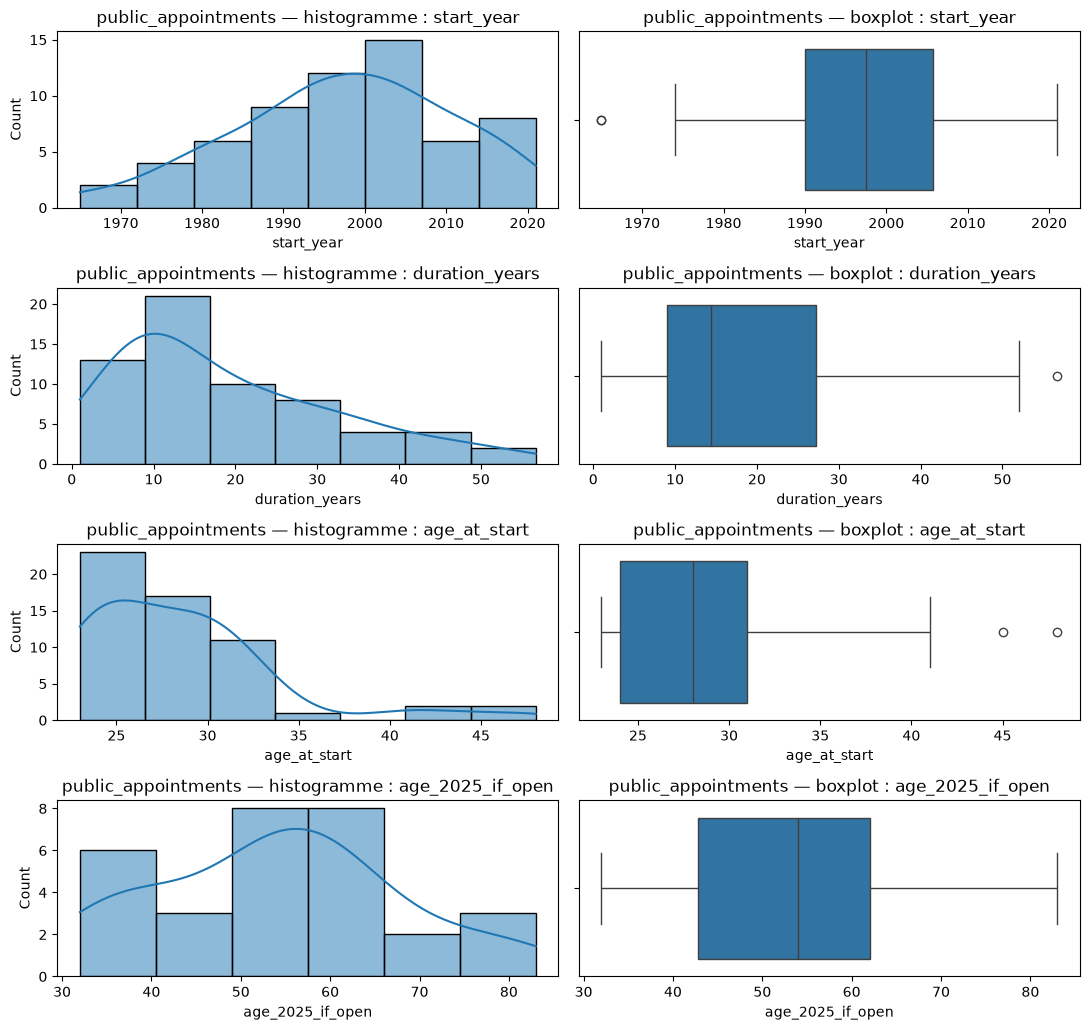

In [16]:
distributions(ap, num_ap, "public_appointments")

- `start_year` (1965–2021, médiane 1997) est la seule variable compatible avec une loi normale (Shapiro p = 0,25). Pas de point historique extrême, contrairement à `officer_filings`.
- `duration_years` est asymétrique à droite (skewness 0,95) : médiane 14 ans, mais une poignée de mandats dépasse 40 ans (Elira Vaun 56,7 ans ; Mirek Talven 52 ; Leora Kassen 48 ; Zalia Maren 46).
- `age_at_start` (médiane 28 ans) a une queue à droite : quelques nominations tardives aux plus hauts postes (Mirek Talven à 48 ans, Elira Vaun à 45).
- `age_2025_if_open` : les titulaires encore en poste ont jusqu'à **83 ans** (Mirek Talven, gouverneur régional depuis 1974), puis 78 ans (Leora Kassen, cheffe du gouvernement kintaran depuis 1978). Ce sont des âges plausibles, mais des durées au sommet très inhabituelles : à étudier au bloc 3.

### 2.4 Variables catégorielles

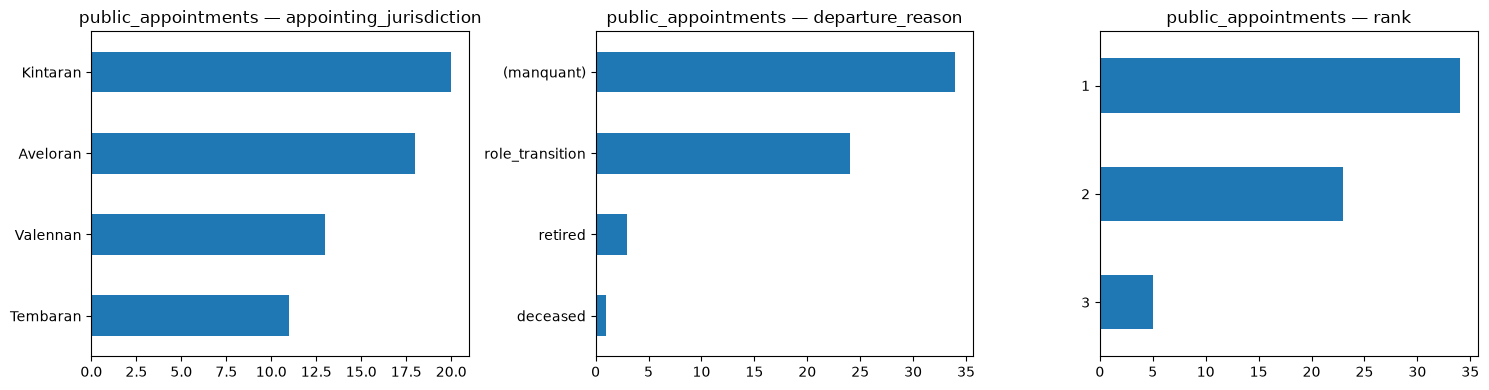

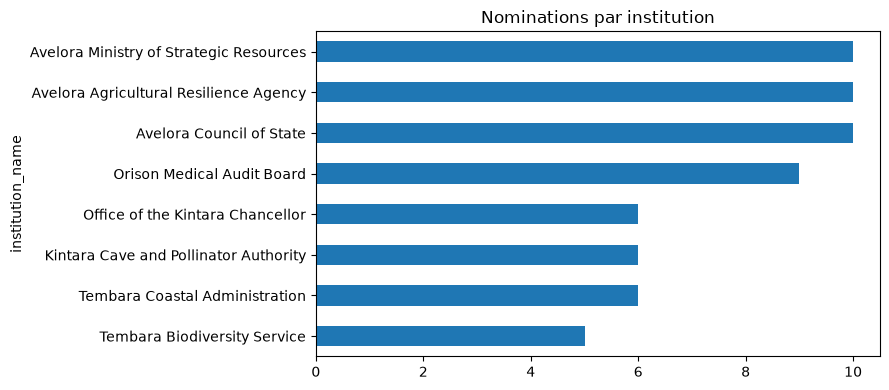

In [17]:
barplots(ap, ["appointing_jurisdiction", "departure_reason", "rank"], "public_appointments")
ap["institution_name"].value_counts().sort_values().plot.barh(figsize=(9, 4), title="Nominations par institution")
plt.tight_layout(); plt.show()

- **Juridiction** : Kintaran 20, Aveloran 18, Valennan 13, Tembaran 11.
- **Motif de départ** : 34 mandats en cours, 24 `role_transition` (passage à un autre poste), 3 retraites, 1 décès (Elira Vaun, 2021).
- **Niveau** : 34 agents, 23 cadres, 5 postes au sommet de l'État.
- **Institutions** : les trois institutions avelorannes ont 10 nominations chacune, alors que l'Avelora n'a que 18 nominations : des Kintarans et des Valennans occupent des postes en Avelora (vu au bloc 3).

### 2.5 Corrélations

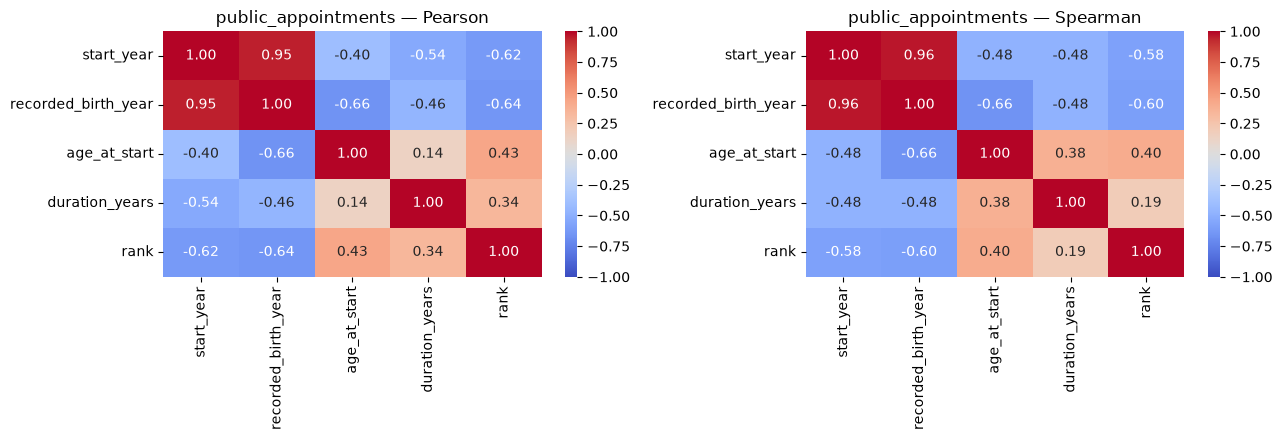

In [18]:
corr_ap = ["start_year", "recorded_birth_year", "age_at_start", "duration_years", "rank"]
correlations(ap, corr_ap, "public_appointments")

- `start_year` ↔ `recorded_birth_year` (0,95 / 0,96) : relation de construction.
- `rank` est corrélé négativement à `start_year` (−0,62 / −0,58) et positivement à `age_at_start` (0,43 / 0,40) : les plus hauts postes ont été attribués **plus tôt** et à des personnes **plus âgées**.
- `rank` ↔ `duration_years` est faible (0,34 en Pearson, 0,19 en Spearman) : l'écart montre que le lien vient de **quelques mandats très longs** au sommet, pas d'une tendance générale.

---
## 3. licensed_facilities

In [19]:
fac = facilities.copy()
fac["operateur"] = fac["operating_organization_registration"].map(reg_name)
display(inventaire(fac))
fac[["facility_license_number", "facility_name", "facility_category", "operateur", "region", "latitude", "longitude", "license_start", "facility_status", "declared_services"]]

Dimensions : (3, 13)


,type,valeurs_distinctes,manquants
facility_license_number,str,3,0
facility_name,str,3,0
facility_category,str,3,0
operating_organization_registration,str,2,0
street_address,str,3,0
region,str,2,0
latitude,float64,3,0
longitude,float64,3,0
license_start,datetime64[us],3,0
license_end,float64,0,3


,facility_license_number,facility_name,facility_category,operateur,region,latitude,longitude,license_start,facility_status,declared_services
0,FAC-VLN-101,Asterion Central Clinical Campus,research_hospital,Asterion Clinical Institute,Valenne Republic,47.20,7.51,2001-02-01,active,preventive medicine; cardiac assessment; clini...
1,FAC-AVL-201,Asterion Avelora Executive Clinic,private_clinic,Asterion Clinical Institute,Avelora Federation,7.35,101.62,2008-05-15,active,executive health; specialist follow-up; outpat...
2,FAC-AVL-301,Threshold Earth Avelora Laboratory,research_laboratory,Threshold Earth Observatory,Avelora Federation,7.50,101.75,2012-01-18,active,environmental health research; non-invasive hu...


**3 établissements seulement** : les statistiques descriptives, distributions et corrélations n'ont pas de sens, on décrit directement les lignes.
- `license_end` est vide et `facility_status` vaut « active » partout : variables **constantes**.
- **Asterion Clinical Institute** (enregistré en Valenne) exploite deux sites : son campus en Valenne et une clinique « executive health » en Avelora, ouverte en 2008.
- La clinique aveloranne et le laboratoire Threshold Earth sont tous deux dans l'*Eastern Avelora Agricultural Cluster*, à environ 22 km l'un de l'autre (coordonnées fictives : on n'interprète que les distances relatives).
- Le laboratoire **environnemental** Threshold Earth déclare un service de *non-invasive human assessment* : atypique pour ce type de laboratoire.

---
## 4. licensed_professionals
### 4.1 Inventaire et typage

In [20]:
inventaire(professionals)

Dimensions : (53, 10)


,type,valeurs_distinctes,manquants
license_number,str,53,0
professional_name,str,53,0
profession,str,5,0
specialty,str,15,0
license_issue_date,datetime64[us],39,0
license_expiry_date,float64,0,53
license_status,str,1,0
primary_facility_license,str,3,26
registered_region,str,5,0
disciplinary_status,str,2,0


- 53 professionnels, un par ligne.
- `license_status` est **constante** (« active ») et `license_expiry_date` est **vide** : on les écarte.
- `primary_facility_license` est vide pour les administratifs et les juristes (ils n'exercent pas dans un établissement) : manque **structurel**, recodé en « aucun ».

**Typage** : identifiants (`license_number`, `professional_name`) ; nominales (`profession` 5, `specialty`, `primary_facility_license`, `registered_region` 5, `disciplinary_status`) ; une date (`license_issue_date`). C'est la seule variable numérique après transformation : **pas de matrice de corrélation possible**.

### 4.2 Variables construites et distribution

In [21]:
lp = professionals.copy()
lp["facility"] = lp["primary_facility_license"].fillna("aucun")
lp["issue_year"] = lp["license_issue_date"].dt.year
lp["licence_age_2025"] = REF_DATE.year - lp["issue_year"]
print("Mois / jour de délivrance :", lp["license_issue_date"].dt.strftime("%m-%d").unique().tolist())
describe_numeric(lp, ["issue_year"])

Mois / jour de délivrance : ['07-01']


,n,manquants,moyenne,écart-type,min,Q1,médiane,Q3,max,skewness,shapiro_p
issue_year,53,0,1996.057,26.405,1886,1994.0,2002.0,2009.0,2026,-2.894,0.0


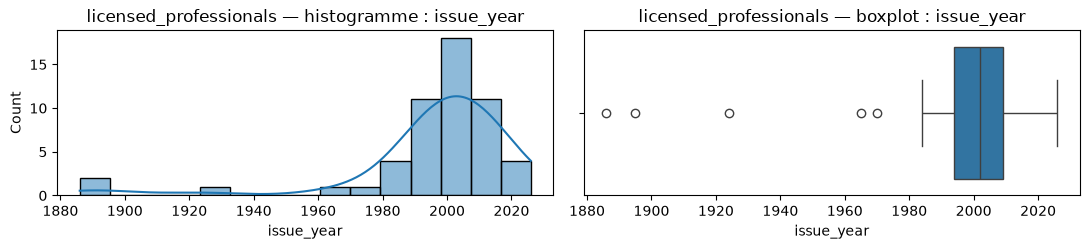

In [22]:
distributions(lp, ["issue_year"], "licensed_professionals")

- Toutes les licences sont délivrées un **1er juillet** : artefact de génération.
- `issue_year` est très asymétrique vers la gauche (skewness −2,9) : médiane 2002, mais **cinq licences très anciennes** (J. Varlan 1886, Emil Warden 1895, Jonah Bell 1924, Elira Vaun 1965, Julien Marot 1970), toutes encore « active ». On retrouve les noms des nominations anciennes de `officer_filings`.
- La licence la plus récente est datée de **2026** (Farah Havel), après la date de référence.

### 4.3 Variables catégorielles

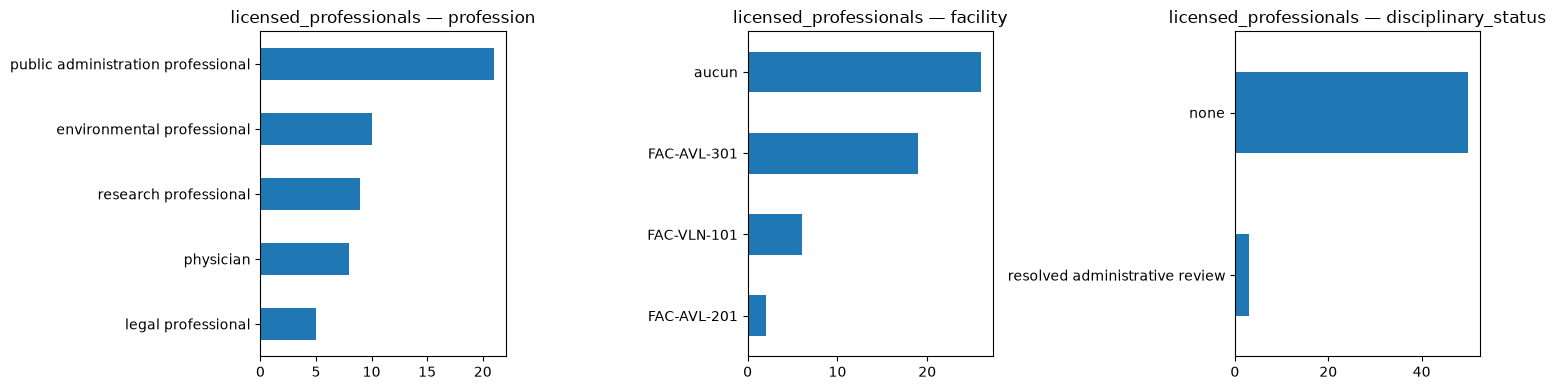

facility,FAC-AVL-201,FAC-AVL-301,FAC-VLN-101,aucun
profession,,,,
environmental professional,0,10,0,0
legal professional,0,0,0,5
physician,2,0,6,0
public administration professional,0,0,0,21
research professional,0,9,0,0


In [23]:
barplots(lp, ["profession", "facility", "disciplinary_status"], "licensed_professionals")
pd.crosstab(lp["profession"], lp["facility"])

- **Profession** : administrateurs publics 21, environnementalistes 10, chercheurs 9, médecins 8, juristes 5.
- Le tableau profession × établissement est très structuré : les administrateurs et les juristes n'ont pas d'établissement, les médecins sont chez Asterion (6 sur le campus FAC-VLN-101, 2 à la clinique aveloranne FAC-AVL-201), environnementalistes et chercheurs au laboratoire FAC-AVL-301.
- Parmi les chercheurs du laboratoire **environnemental**, 2 sont en **recherche clinique** : cohérent avec son service de *non-invasive human assessment*.
- **Statut disciplinaire** : 50 « none », 3 *resolved administrative review*.

---
## 5. institutional_memos et 6. public_and_investigative_documents
Ces deux fichiers sont **textuels** : l'analyse du texte relève du bloc 6. Ici, on explore les métadonnées et quelques mesures simples sur les textes. Ils ont la même structure, on les traite ensemble.
### 5.1 Inventaire et typage

In [24]:
display(inventaire(memos))
display(inventaire(documents))

Dimensions : (30, 12)


,type,valeurs_distinctes,manquants
document_id,str,30,0
document_date,datetime64[us],30,0
document_type,str,6,0
author_name,str,27,0
author_organization,str,13,0
recipient_text,str,2,0
subject_line,str,30,0
text,str,30,0
related_purchase_order,str,5,25
related_shipment_number,str,8,22


Dimensions : (40, 11)


,type,valeurs_distinctes,manquants
document_id,str,40,0
document_date,datetime64[us],40,0
collection,str,6,0
document_type,str,16,0
author_name,str,32,1
author_organization,str,22,0
named_location,str,14,0
title,str,40,0
text,str,40,0
public_or_restricted,str,2,0


- **memos** (30) : identifiant, date, type (6), auteur, organisation, destinataire, objet, texte, trois colonnes de rattachement (`related_purchase_order`, `related_shipment_number`, `related_case_number`, souvent vides car un memo n'est rattaché qu'à un seul type de dossier) et la visibilité (3 niveaux).
- **documents publics** (40) : identifiant, date, collection (6), type (16), auteur (1 manquant), organisation, lieu, titre, texte, visibilité (2 niveaux) et référence source.

### 5.2 Variables construites et distributions

In [25]:
mem = memos.rename(columns={"visibility_level": "visibility"}).assign(source="memos")
pub = documents.rename(columns={"public_or_restricted": "visibility"}).assign(source="public_docs")
docs = pd.concat([mem, pub], ignore_index=True)
docs["year"] = docs["document_date"].dt.year
docs["n_words"] = docs["text"].str.split().str.len()
# paragraphes (séparés par une ligne vide) et paragraphes répétés dans le même document
paragraphes = docs["text"].apply(lambda t: [p.strip() for p in re.split(r"\n\s*\n", t) if p.strip()])
docs["n_paragraphs"] = paragraphes.apply(len)
docs["n_dup_paragraphs"] = paragraphes.apply(lambda ps: len(ps) - len(set(ps)))
print("Caractères non ASCII :", sorted({ch for t in docs["text"] for ch in t if ord(ch) > 127}))
describe_numeric(docs, ["year", "n_words", "n_paragraphs", "n_dup_paragraphs"])

Caractères non ASCII : ['–', '—', '“', '”']


,n,manquants,moyenne,écart-type,min,Q1,médiane,Q3,max,skewness,shapiro_p
year,70,0,2014.500,21.132,1914,2019.0,2021.0,2024.0,2025,-3.017,0.0
n_words,70,0,169.657,61.531,82,122.0,141.5,218.5,290,0.456,0.0
n_paragraphs,70,0,11.271,5.723,3,8.0,9.0,14.0,23,0.860,0.0
n_dup_paragraphs,70,0,2.800,4.402,0,0.0,0.0,4.0,13,1.297,0.0


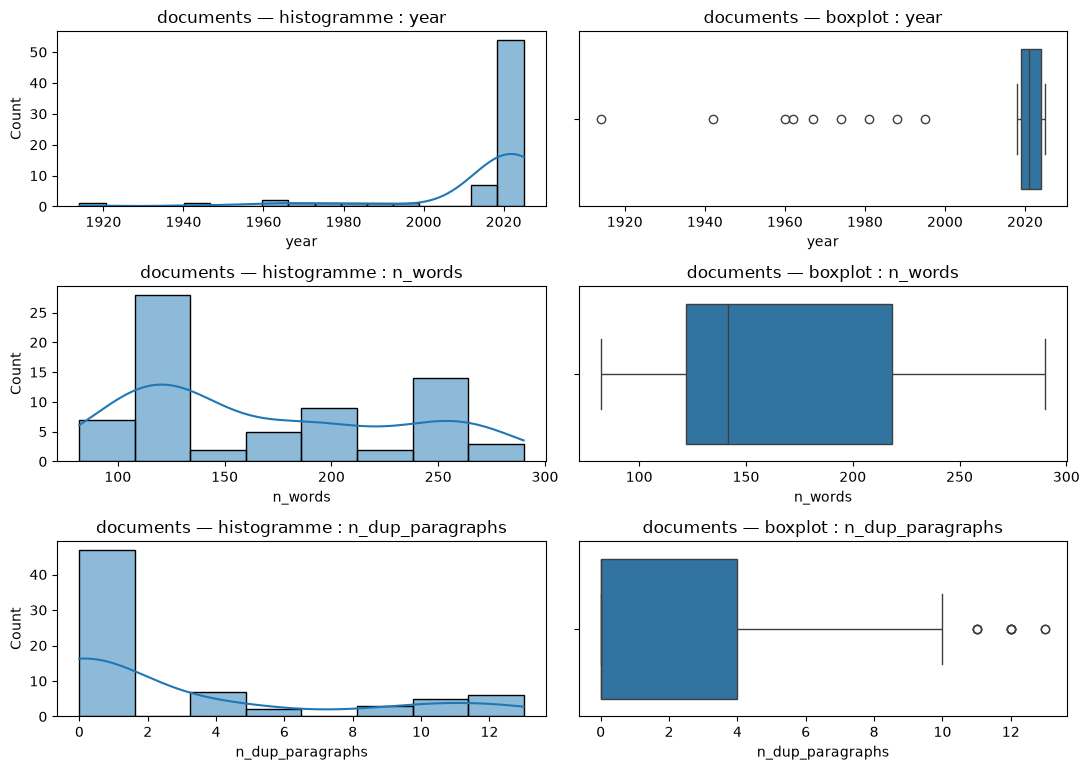

In [26]:
distributions(docs, ["year", "n_words", "n_dup_paragraphs"], "documents")

- Le corpus est en anglais, encodé en UTF-8 (seuls caractères non ASCII : tirets et guillemets typographiques).
- **Dates** : les memos vont de 2018 à 2025 ; les documents publics de **1914 à 2025**, avec 9 documents antérieurs à 2000 (archives historiques : lettres, extraits de réunions, registres).
- **Longueur** : 82 à 290 mots, pas de valeur extrême. Les memos sont plus courts (médiane 126 mots) que les documents publics (199).
- **Paragraphes répétés** : 23 documents publics sur 40 et 4 memos répètent mot pour mot certains paragraphes (jusqu'à 13 répétitions). Ce texte « gabarit » faussera les fréquences de mots : il faudra le **dédoublonner avant le bloc 6**.

### 5.3 Variables catégorielles

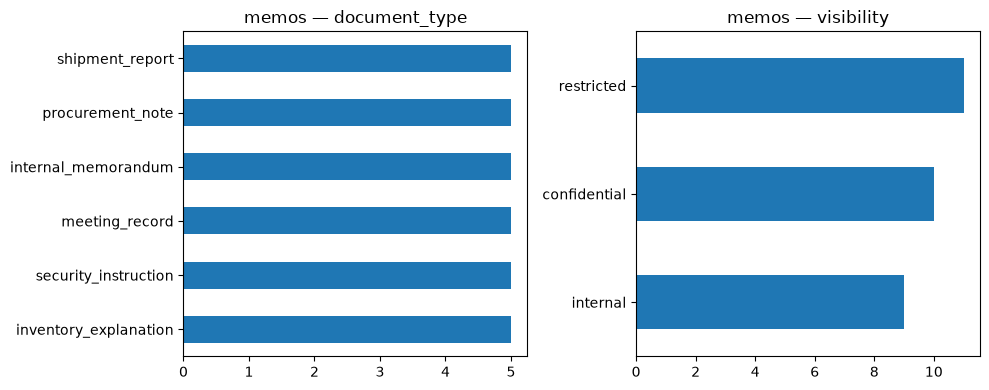

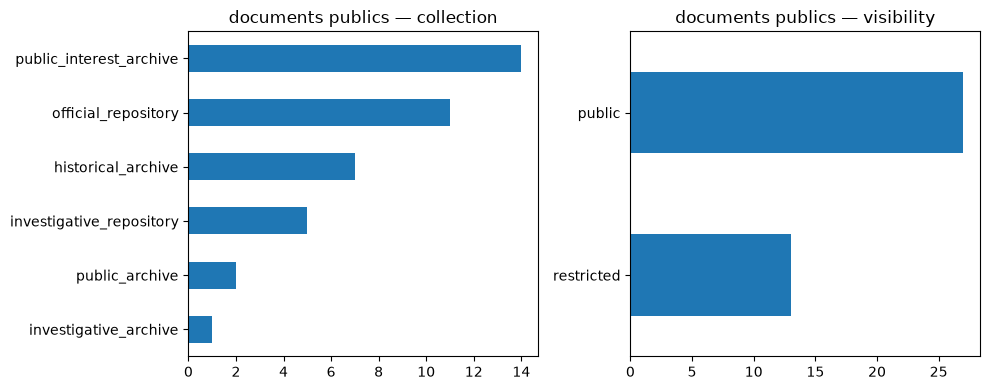

{'confidential_briefing': 3, 'research_summary': 3, 'investigative_note': 3, 'policy_memorandum': 3, 'public_statement': 3, 'campaign_statement': 3, 'open_letter': 3, 'witness_testimony': 3, 'historical_letter': 2, 'meeting_extract': 2, 'whistleblower_message': 2, 'corporate_archive': 2, 'official_correspondence': 2, 'meeting_minutes': 2, 'registry_extract': 2, 'personal_note': 2}


In [27]:
barplots(mem, ["document_type", "visibility"], "memos")
barplots(pub, ["collection", "visibility"], "documents publics")
print(pub["document_type"].value_counts().to_dict())

- **memos** : 6 types × **exactement 5** documents chacun, et une visibilité répartie de façon équilibrée (restricted 11, confidential 10, internal 9). Une répartition aussi régulière évoque un gabarit de génération.
- **documents publics** : 16 types pour 40 documents (2 ou 3 par type) ; collections dominées par `public_interest_archive` (14) et `official_repository` (11) ; 27 publics, 13 restreints.
- Pas de corrélation calculée : les seules variables numériques sont des mesures de texte, liées entre elles par construction (plus de paragraphes = plus de mots).